# 10 — Call-Center Simulation (SimPy)

## 1. Introduction and objectives

This notebook (Phase 3) simulates the CallVerse contact center minute by minute with a **discrete-event simulation**: contacts arrive, wait in a queue, may hang up, and are handled by agents. It is the first working version of the *Event simulation* box of the architecture.

The engine is real code in `src/callverse/simulation/` (tested in `tests/unit/test_simulation.py`). This notebook:

1. Checks the engine against the **Erlang C** queueing formula.
2. Builds a **staffing plan** per hour with Erlang C, from the LightGBM forecast (Phase 2).
3. Simulates two 4-week periods, with 10 independent runs each, and reports KPIs with **95% confidence intervals**.
4. Measures the **cost of forecast error**: staffing from the forecast versus staffing from perfect knowledge of daily volume.

**Decisions (agreed for version 1)**

| Topic | Choice |
|---|---|
| Volume | Synthetic contacts × **25** (Olist's public data is a sample) |
| Opening hours | **08:00–22:00**, 7 days. Night contacts wait as a backlog answered from 08:00 |
| Routing | **One FIFO queue**; every agent handles every intent group |
| Staffing | **Erlang C** per hour from the forecast: 80% answered within 20 s, occupancy ≤ 90% |

All other assumptions (handle times, patience) are in `configs/simulation.yaml`.

> Contacts are **synthetic** (notebook 08). The simulation tests decisions on a plausible, documented virtual contact center, not on observed operations.

## 2. Imports, paths and inputs

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy import stats

from callverse.simulation import (
    Contact,
    LognormalServiceModel,
    contact_kpis,
    erlang_c_mean_wait,
    erlang_c_service_level,
    erlang_c_wait_probability,
    generate_contacts,
    load_simulation_config,
    plan_hourly_staffing,
    run_simulation,
    summarize_replications,
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
CONFIG_FILE = PROJECT_ROOT / "configs" / "simulation.yaml"

required_files = [
    CONFIG_FILE,
    PROCESSED_DIR / "synthetic_contacts_daily_by_group.parquet",
    PROCESSED_DIR / "contact_hour_profile.csv",
    ARTIFACTS_DIR / "forecasts" / "contact_forecast_backtest_predictions.parquet",
]
missing_files = [str(path) for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Missing inputs: {missing_files}. Run notebooks 06, 08 and 09 first.")

config = load_simulation_config(CONFIG_FILE)
with open(CONFIG_FILE, encoding="utf-8") as config_file:
    erlang_check = yaml.safe_load(config_file)["validation"]["erlang_check"]
service_model = LognormalServiceModel(config.service_times)

actual_daily = pd.read_parquet(PROCESSED_DIR / "synthetic_contacts_daily_by_group.parquet")
hour_shares = pd.read_csv(PROCESSED_DIR / "contact_hour_profile.csv").sort_values("hour")["share"].to_numpy()
hour_shares = hour_shares / hour_shares.sum()
backtest = pd.read_parquet(ARTIFACTS_DIR / "forecasts" / "contact_forecast_backtest_predictions.parquet")
forecast_daily = backtest[(backtest["model"] == "lightgbm") & (backtest["intent_group"] != "total")]
forecast_daily = forecast_daily[["date", "intent_group", "forecast"]].rename(columns={"forecast": "contacts"})

if forecast_daily.duplicated(["date", "intent_group"]).any():
    raise ValueError("Each day and group must have exactly one forecast.")
if set(config.service_times) != set(actual_daily["intent_group"]):
    raise ValueError("Every intent group needs a handle-time assumption in simulation.yaml.")

assumption_rows = [{"intent_group": group, "mean_handle_minutes": spec.mean_seconds / 60, "cv": spec.cv}
                   for group, spec in config.service_times.items()]
display(pd.DataFrame(assumption_rows))
print(f"Scale x{config.scale_factor:g} | open {config.open_hour}:00-{config.close_hour}:00 | "
      f"target {config.service_level_target:.0%} in {config.service_level_threshold_seconds:g}s | "
      f"patience mean {config.patience_mean_seconds:g}s | replications {config.replications}")

,intent_group,mean_handle_minutes,cv
0,wismo,3.0,0.6
1,order_admin,4.0,0.6
2,cancel_refund,6.0,0.6
3,post_delivery,7.0,0.6


Scale x25 | open 8:00-22:00 | target 80% in 20s | patience mean 180s | replications 10


## 3. Engine check against Erlang C

Erlang C is the textbook formula for a queue with random (Poisson) arrivals, exponential handle times, *c* agents and no hang-ups. In exactly that setting, the simulator must reproduce the formula. If it does, the queue, agent and timing logic can be trusted.

The setting comes from `validation.erlang_check` in the config: constant arrivals over many hours, without opening hours or abandonment. The first 10 hours are skipped as warm-up, because the queue starts empty.

In [2]:
rate = erlang_check["arrival_rate_per_hour"]
mean_service = erlang_check["mean_service_seconds"]
agents = erlang_check["agents"]
hours = erlang_check["hours"]
threshold = config.service_level_threshold_seconds
WARM_UP_SECONDS = 10 * 3600

check_runs = []
for replication in range(erlang_check["replications"]):
    rng = np.random.default_rng(config.random_seed + 1000 + replication)
    arrivals = np.cumsum(rng.exponential(3600 / rate, int(rate * hours * 1.2)))
    arrivals = arrivals[arrivals < (hours - 2) * 3600]
    services = rng.exponential(mean_service, len(arrivals))
    contacts = [Contact(i, float(t), "check", float(s), True, None)
                for i, (t, s) in enumerate(zip(arrivals, services))]
    records = run_simulation(contacts, np.full(hours, agents))
    steady = records[records["arrival"] > WARM_UP_SECONDS]
    check_runs.append({"replication": replication, "check": "erlang",
                       "wait_probability": (steady["wait"] > 1e-9).mean(),
                       "mean_wait_seconds": steady["wait"].mean(),
                       "service_level": (steady["wait"] <= threshold).mean()})

check_summary = summarize_replications(pd.DataFrame(check_runs), config.confidence_level, ["check"])
load = rate * mean_service / 3600
theory = {"wait_probability": erlang_c_wait_probability(agents, load),
          "mean_wait_seconds": erlang_c_mean_wait(agents, rate, mean_service),
          "service_level": erlang_c_service_level(agents, rate, mean_service, threshold)}
check_summary["erlang_c"] = check_summary["kpi"].map(theory)
check_summary["formula_inside_ci"] = check_summary["erlang_c"].between(check_summary["ci_low"], check_summary["ci_high"])
print(f"Setting: {rate}/hour, mean handle {mean_service}s, {agents} agents, load {load:.2f} Erlangs, {hours} hours x {erlang_check['replications']} runs")
display(check_summary[["kpi", "mean", "ci_low", "ci_high", "erlang_c", "formula_inside_ci"]].round(4))

Setting: 60/hour, mean handle 240s, 6 agents, load 4.00 Erlangs, 400 hours x 10 runs


,kpi,mean,ci_low,ci_high,erlang_c,formula_inside_ci
0,wait_probability,0.2852,0.2799,0.2905,0.2848,True
1,mean_wait_seconds,33.6772,32.1133,35.2412,34.1713,True
2,service_level,0.7589,0.7542,0.7636,0.7590,True


If the formula value lies inside the 95% confidence interval of the simulation for each measure, the simulator behaves like the theory. With 10 runs and 3 measures, one value falling just outside by chance would not be alarming; a large gap would point to a bug.

## 4. Staffing plans

For each simulated hour we compute the **expected arrivals** and the **average handle time** given the intent mix, then the minimum number of agents meeting the target (Erlang C, `plan_hourly_staffing`).

- Expected arrivals = daily contacts per group × scale × hourly share.
- **Night backlog.** Contacts expected between 22:00 and 08:00 are added to the planned workload of the first `backlog_spread_hours` open hours (08:00–10:00), so the morning team is sized for them.
- Two plans are built from the same method:
  - **forecast plan**: daily contacts from the LightGBM 1–7-day-ahead forecast, which is what a planner would really know;
  - **perfect-information plan**: daily contacts from the actual series. It still does not know the random variation inside each day; it isolates the effect of forecast error.

Simulated arrivals always come from the **actual** daily contacts, the same draws for both plans in each run (*common random numbers*), so the two plans are compared on identical customers.

In [3]:
PERIODS = {
    "december_2017_wave": (pd.Timestamp("2017-12-04"), pd.Timestamp("2017-12-31")),
    "normal_may_2018": (pd.Timestamp("2018-05-07"), pd.Timestamp("2018-06-03")),
}
DRAIN_DAYS = 1  # one extra simulated day so the last evening's backlog can be served

def hourly_plan_inputs(daily_counts, days):
    # Expected arrivals and mean handle time for every hour of the given days
    hours_total = len(days) * 24
    arrivals = np.zeros(hours_total)
    work_seconds = np.zeros(hours_total)
    for row in daily_counts[daily_counts["date"].isin(days)].itertuples():
        day_index = days.get_loc(row.date)
        hourly = row.contacts * config.scale_factor * hour_shares
        slots = slice(day_index * 24, day_index * 24 + 24)
        arrivals[slots] += hourly
        work_seconds[slots] += hourly * config.service_times[row.intent_group].mean_seconds

    open_mask = np.array([config.is_open(hour % 24) for hour in range(hours_total)])
    planned = arrivals.copy()
    planned_work = work_seconds.copy()
    for day_index in range(len(days)):
        night = [hour for hour in range(day_index * 24 - 24 + config.close_hour, day_index * 24 + config.open_hour)
                 if 0 <= hour < hours_total]
        backlog_arrivals = arrivals[night].sum()
        backlog_work = work_seconds[night].sum()
        morning = [day_index * 24 + config.open_hour + k for k in range(config.backlog_spread_hours)]
        for hour in morning:
            planned[hour] += backlog_arrivals / config.backlog_spread_hours
            planned_work[hour] += backlog_work / config.backlog_spread_hours
    mean_handle = np.divide(planned_work, planned, out=np.full(hours_total, 240.0), where=planned > 0)
    return planned, mean_handle, open_mask

plans = {}
plan_rows = []
for period_name, (first_day, last_day) in PERIODS.items():
    days = pd.date_range(first_day, last_day + pd.Timedelta(days=DRAIN_DAYS))
    for plan_name, source in [("forecast_plan", forecast_daily), ("perfect_information_plan", actual_daily)]:
        missing_days = set(days) - set(source["date"])
        if missing_days:
            raise ValueError(f"{plan_name}: no daily contacts for {sorted(missing_days)[:3]}")
        planned, mean_handle, open_mask = hourly_plan_inputs(source, days)
        staffing = plan_hourly_staffing(planned, mean_handle, open_mask, config.service_level_target,
                                        config.service_level_threshold_seconds, config.max_occupancy,
                                        config.min_agents)
        plans[(period_name, plan_name)] = staffing
        plan_rows.append({"period": period_name, "plan": plan_name, "days": len(days) - DRAIN_DAYS,
                          "agent_hours": int(staffing[: (len(days) - DRAIN_DAYS) * 24].sum()),
                          "max_agents_in_an_hour": int(staffing.max()),
                          "planned_contacts": round(planned[: (len(days) - DRAIN_DAYS) * 24].sum())})
display(pd.DataFrame(plan_rows))

,period,plan,days,agent_hours,max_agents_in_an_hour,planned_contacts
0,december_2017_wave,forecast_plan,28,2418,13,22806
1,december_2017_wave,perfect_information_plan,28,2363,14,22120
2,normal_may_2018,forecast_plan,28,2193,10,17934
3,normal_may_2018,perfect_information_plan,28,1972,11,15869


In [4]:
# Example: the forecast plan for the first two days of the December period
example = plans[("december_2017_wave", "forecast_plan")][:48]
example_table = pd.DataFrame({"hour": list(range(24)), "day_1_agents": example[:24], "day_2_agents": example[24:]})
display(example_table.set_index("hour").T)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_1_agents,0,0,0,0,0,0,0,0,4,5,...,5,5,5,4,4,4,4,4,0,0
day_2_agents,0,0,0,0,0,0,0,0,6,7,...,4,4,4,4,4,4,4,4,0,0


## 5. Simulation runs

For each period and each of the 10 runs: draw the contacts (scaled Poisson arrivals from the actual daily series, handle times, patience), then simulate the same contacts under both staffing plans. Only contacts arriving during the period are scored; the drain day lets the last night's backlog be served.

In [5]:
run_rows = []
daily_rows = []
hourly_rows = []
trace_example = None

for period_name, (first_day, last_day) in PERIODS.items():
    days = pd.date_range(first_day, last_day + pd.Timedelta(days=DRAIN_DAYS))
    evaluation_end = (len(days) - DRAIN_DAYS) * 86400
    period_actual = actual_daily[actual_daily["date"].isin(days)]
    for replication in range(config.replications):
        rng = np.random.default_rng(config.random_seed + replication)
        contacts = generate_contacts(period_actual, hour_shares, first_day, config, service_model, rng)
        for plan_name in ["forecast_plan", "perfect_information_plan"]:
            staffing = plans[(period_name, plan_name)]
            records = run_simulation(contacts, staffing)
            kpis = contact_kpis(records, staffing[: len(days) * 24], config.service_level_threshold_seconds,
                                evaluation_end=evaluation_end)
            run_rows.append({"period": period_name, "plan": plan_name, "replication": replication, **kpis})

            scored = records[records["arrival"] < evaluation_end].copy()
            scored["day"] = (scored["arrival"] // 86400).astype(int)
            scored["hour_of_day"] = (scored["arrival"] % 86400 // 3600).astype(int)
            live = scored[scored["is_live"]]
            in_time = live["start"].notna() & (live["wait"] <= config.service_level_threshold_seconds)
            labels = {"period": period_name, "plan": plan_name, "replication": replication}
            per_day = in_time.groupby(live["day"]).mean().rename("service_level").reset_index()
            daily_rows.append(per_day.assign(**labels))
            per_hour = pd.DataFrame({"service_level": in_time.groupby(live["hour_of_day"]).mean(),
                                     "abandon_rate": live["abandoned"].groupby(live["hour_of_day"]).mean(),
                                     "live_contacts": live.groupby("hour_of_day").size()}).reset_index()
            hourly_rows.append(per_hour.assign(**labels))
            if trace_example is None:
                trace_example = records.assign(period=period_name, plan=plan_name, replication=replication)

runs = pd.DataFrame(run_rows)
daily_service = pd.concat(daily_rows, ignore_index=True)
hourly_service = pd.concat(hourly_rows, ignore_index=True)
print("Simulation runs:", len(runs), "| contacts simulated per run (mean):", round(runs["offered"].mean()))

Simulation runs: 40 | contacts simulated per run (mean): 16331


In [6]:
# Integrity checks on every run
integrity = [
    ("Every scored contact was answered or abandoned (none left unfinished)", bool((runs["unfinished"] == 0).all())),
    ("Service level, abandon rate and occupancy are between 0 and 1",
     bool(runs[["service_level", "abandon_rate", "occupancy"]].stack().between(0, 1).all())),
    ("Both plans saw identical contacts in each run",
     bool(runs.groupby(["period", "replication"])["offered"].nunique().eq(1).all())),
    ("10 runs per period and plan", bool(runs.groupby(["period", "plan"]).size().eq(config.replications).all())),
]
display(pd.DataFrame(integrity, columns=["check", "passed"]))

,check,passed
0,Every scored contact was answered or abandoned...,True
1,"Service level, abandon rate and occupancy are ...",True
2,Both plans saw identical contacts in each run,True
3,10 runs per period and plan,True


## 6. Results

### 6.1 KPIs with 95% confidence intervals

| KPI | Meaning | Target or benchmark |
|---|---|---|
| `service_level` | live contacts answered within 20 s | ≥ 80% (target used for staffing) |
| `abandon_rate` | live contacts that hung up | ≤ 5% (retail benchmark) |
| `asa_seconds` | average speed of answer, answered live contacts | 20–30 s (retail benchmark) |
| `backlog_wait_hours` | average wait of night contacts until answered | — |
| `occupancy` | share of staffed time spent handling contacts | ≤ 90% (planning limit) |
| `agent_hours` | staffed agent-hours over the 4 weeks | cost driver |

In [7]:
summary = summarize_replications(runs, config.confidence_level, ["period", "plan"])
summary["value"] = summary.apply(lambda row: f"{row['mean']:.3g} [{row['ci_low']:.3g}, {row['ci_high']:.3g}]", axis=1)
kpi_order = ["service_level", "abandon_rate", "asa_seconds", "backlog_wait_hours", "occupancy", "agent_hours", "offered"]
results = summary.pivot(index="kpi", columns=["period", "plan"], values="value").loc[kpi_order]
display(results)

means = summary.pivot(index=["period", "plan"], columns="kpi", values="mean")
benchmark = pd.DataFrame({
    "service_level_target_met": means["service_level"] >= config.service_level_target,
    "abandon_within_5_percent": means["abandon_rate"] <= 0.05,
    "occupancy_within_limit": means["occupancy"] <= config.max_occupancy,
})
display(benchmark)

period                         december_2017_wave  \
plan                                forecast_plan   
kpi                                                 
service_level                0.831 [0.826, 0.835]   
abandon_rate              0.0801 [0.0784, 0.0818]   
asa_seconds                     13.9 [10.1, 17.7]   
backlog_wait_hours              7.93 [7.89, 7.96]   
occupancy                    0.522 [0.519, 0.525]   
agent_hours         2.48e+03 [2.48e+03, 2.48e+03]   
offered              1.9e+04 [1.89e+04, 1.91e+04]   

period                                             \
plan                     perfect_information_plan   
kpi                                                 
service_level                 0.88 [0.878, 0.883]   
abandon_rate              0.0588 [0.0577, 0.0599]   
asa_seconds                     7.91 [5.19, 10.6]   
backlog_wait_hours              7.89 [7.86, 7.93]   
occupancy                     0.544 [0.54, 0.547]   
agent_hours         2.43e+03 [2.43e+03, 2.43e+03]   
offered              1.9e+04 [1.89e+04, 1.91e+04]   

period                            normal_may_2018  \
plan                                forecast_plan   
kpi                                                 
service_level                0.902 [0.899, 0.905]   
abandon_rate              0.0504 [0.0486, 0.0522]   
asa_seconds                       7.47 [3.94, 11]   
backlog_wait_hours              7.78 [7.74, 7.82]   
occupancy                    0.453 [0.451, 0.455]   
agent_hours         2.25e+03 [2.25e+03, 2.25e+03]   
offered             1.37e+04 [1.36e+04, 1.37e+04]   

period                                             
plan                     perfect_information_plan  
kpi                                                
service_level                 0.887 [0.885, 0.89]  
abandon_rate               0.0568 [0.055, 0.0587]  
asa_seconds                      9.8 [6.04, 13.6]  
backlog_wait_hours              7.81 [7.77, 7.85]  
occupancy                      0.498 [0.496, 0.5]  
agent_hours         2.04e+03 [2.04e+03, 2.04e+03]  
offered             1.37e+04 [1.36e+04, 1.37e+04]

service_level_target_met  \
period             plan                                                 
december_2017_wave forecast_plan                                 True   
                   perfect_information_plan                      True   
normal_may_2018    forecast_plan                                 True   
                   perfect_information_plan                      True   

                                             abandon_within_5_percent  \
period             plan                                                 
december_2017_wave forecast_plan                                False   
                   perfect_information_plan                     False   
normal_may_2018    forecast_plan                                False   
                   perfect_information_plan                     False   

                                             occupancy_within_limit  
period             plan                                              
december_2017_wave forecast_plan                               True  
                   perfect_information_plan                    True  
normal_may_2018    forecast_plan                               True  
                   perfect_information_plan                    True

### 6.2 Cost of forecast error

The two plans faced the same customers, so their differences come only from staffing. The perfect-information plan shows what the same Erlang C method achieves when the daily volume is known exactly.

In [8]:
comparison_rows = []
for period_name in PERIODS:
    forecast_runs = runs[(runs["period"] == period_name) & (runs["plan"] == "forecast_plan")].set_index("replication")
    perfect_runs = runs[(runs["period"] == period_name) & (runs["plan"] == "perfect_information_plan")].set_index("replication")
    for kpi in ["service_level", "abandon_rate", "asa_seconds", "agent_hours"]:
        difference = forecast_runs[kpi] - perfect_runs[kpi]  # paired by run (same contacts)
        t_value = stats.t.ppf((1 + config.confidence_level) / 2, len(difference) - 1)
        half_width = t_value * difference.std(ddof=1) / np.sqrt(len(difference))
        comparison_rows.append({"period": period_name, "kpi": kpi,
                                "forecast_minus_perfect": round(difference.mean(), 4),
                                "ci_low": round(difference.mean() - half_width, 4),
                                "ci_high": round(difference.mean() + half_width, 4)})
display(pd.DataFrame(comparison_rows))

,period,kpi,forecast_minus_perfect,ci_low,ci_high
0,december_2017_wave,service_level,-0.0496,-0.0521,-0.0471
1,december_2017_wave,abandon_rate,0.0213,0.0200,0.0227
2,december_2017_wave,asa_seconds,5.9747,2.8689,9.0805
3,december_2017_wave,agent_hours,52.0000,52.0000,52.0000
4,normal_may_2018,service_level,0.0147,0.0123,0.0171
5,normal_may_2018,abandon_rate,-0.0064,-0.0073,-0.0056
6,normal_may_2018,asa_seconds,-2.3244,-4.0061,-0.6427
7,normal_may_2018,agent_hours,209.0000,209.0000,209.0000


### 6.3 Daily service level in the December 2017 wave

Mean over the 10 runs. Days where the forecast under-estimated the volume show up as dips below the 80% target.

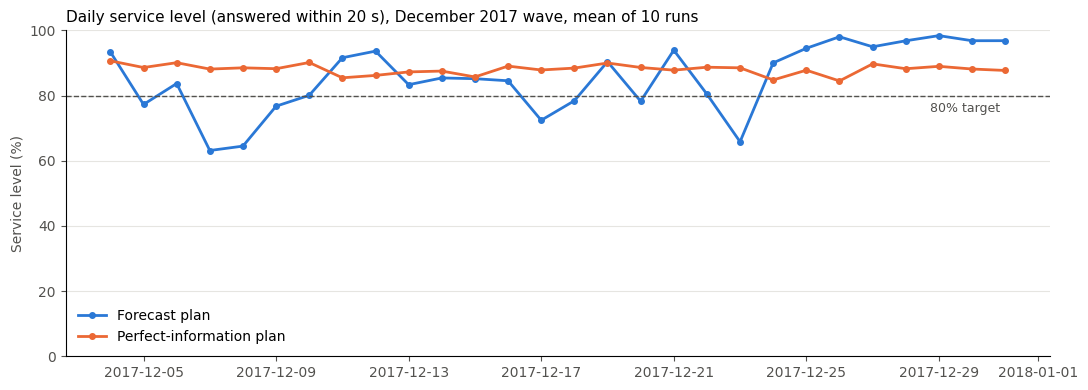

Five worst days for the forecast plan:


plan,forecast_plan,perfect_information_plan
2017-12-07,0.631,0.881
2017-12-08,0.645,0.885
2017-12-23,0.658,0.885
2017-12-17,0.724,0.878
2017-12-09,0.767,0.882


In [9]:
ACTUAL_PLAN_COLOR = "#2a78d6"   # reference categorical slot 1
PERFECT_PLAN_COLOR = "#eb6834"  # reference categorical slot 2
TEXT_SECONDARY = "#52514e"

december_days = pd.date_range(*PERIODS["december_2017_wave"])
daily_mean = (daily_service[daily_service["period"] == "december_2017_wave"]
              .groupby(["plan", "day"])["service_level"].mean().unstack(0))
daily_mean.index = december_days[daily_mean.index]

figure, axis = plt.subplots(figsize=(11, 4))
axis.plot(daily_mean.index, daily_mean["forecast_plan"] * 100, color=ACTUAL_PLAN_COLOR, linewidth=2,
          marker="o", markersize=4, label="Forecast plan")
axis.plot(daily_mean.index, daily_mean["perfect_information_plan"] * 100, color=PERFECT_PLAN_COLOR, linewidth=2,
          marker="o", markersize=4, label="Perfect-information plan")
axis.axhline(config.service_level_target * 100, color=TEXT_SECONDARY, linewidth=1, linestyle="--")
axis.annotate("80% target", (daily_mean.index[-1], config.service_level_target * 100), xytext=(-4, -12),
              textcoords="offset points", color=TEXT_SECONDARY, fontsize=9, ha="right")
axis.set_title("Daily service level (answered within 20 s), December 2017 wave, mean of 10 runs", loc="left", fontsize=11)
axis.set_ylabel("Service level (%)", color=TEXT_SECONDARY)
axis.set_ylim(0, 100)
axis.grid(axis="y", color="#e6e5e1", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
axis.tick_params(colors=TEXT_SECONDARY)
axis.legend(frameon=False, loc="lower left")
figure.tight_layout()
figure.savefig(ARTIFACTS_DIR / "evaluations" / "simulation_december_service_level.png", dpi=150)
plt.show()

worst_days = daily_mean.sort_values("forecast_plan").head(5).round(3)
print("Five worst days for the forecast plan:")
display(worst_days)

### 6.4 Service level and abandonment by hour of day

The night backlog is served first-come-first-served from 08:00, so live customers who call early queue **behind** it. The tables below test that explanation.

In [10]:
hour_service = (hourly_service.groupby(["period", "plan", "hour_of_day"])["service_level"].mean()
                .unstack("hour_of_day").round(2))
print("Service level by hour of day:")
display(hour_service)

hour_abandon = (hourly_service.groupby(["period", "plan", "hour_of_day"])["abandon_rate"].mean()
                .unstack("hour_of_day").round(3))
print("Abandon rate by hour of day:")
display(hour_abandon)

# Share of abandonments in the first open hour, and the abandon rate without it
first_hour = config.open_hour
hourly_service["abandoned_contacts"] = hourly_service["abandon_rate"] * hourly_service["live_contacts"]
totals = hourly_service.groupby(["period", "plan"]).apply(
    lambda table: pd.Series({
        "share_of_abandonments_in_first_hour": table.loc[table["hour_of_day"] == first_hour, "abandoned_contacts"].sum()
        / table["abandoned_contacts"].sum(),
        "abandon_rate_excluding_first_hour": table.loc[table["hour_of_day"] != first_hour, "abandoned_contacts"].sum()
        / table.loc[table["hour_of_day"] != first_hour, "live_contacts"].sum(),
    }), include_groups=False).round(3)
display(totals)

Service level by hour of day:


hour_of_day                                    8     9     10    11    12  \
period             plan                                                     
december_2017_wave forecast_plan             0.13  0.92  0.86  0.86  0.86   
                   perfect_information_plan  0.14  0.99  0.91  0.91  0.90   
normal_may_2018    forecast_plan             0.25  0.98  0.92  0.93  0.93   
                   perfect_information_plan  0.17  0.99  0.92  0.92  0.91   

hour_of_day                                    13    14    15    16    17  \
period             plan                                                     
december_2017_wave forecast_plan             0.85  0.84  0.86  0.86  0.84   
                   perfect_information_plan  0.90  0.90  0.91  0.91  0.89   
normal_may_2018    forecast_plan             0.92  0.92  0.92  0.93  0.92   
                   perfect_information_plan  0.90  0.90  0.91  0.91  0.91   

hour_of_day                                    18    19    20    21  
period             plan                                              
december_2017_wave forecast_plan             0.86  0.86  0.85  0.84  
                   perfect_information_plan  0.91  0.91  0.90  0.90  
normal_may_2018    forecast_plan             0.90  0.92  0.92  0.93  
                   perfect_information_plan  0.90  0.91  0.91  0.91

Abandon rate by hour of day:


hour_of_day                                     8      9      10     11  \
period             plan                                                   
december_2017_wave forecast_plan             0.832  0.056  0.050  0.051   
                   perfect_information_plan  0.822  0.008  0.030  0.031   
normal_may_2018    forecast_plan             0.713  0.015  0.028  0.024   
                   perfect_information_plan  0.782  0.006  0.030  0.029   

hour_of_day                                     12     13     14     15  \
period             plan                                                   
december_2017_wave forecast_plan             0.051  0.051  0.054  0.050   
                   perfect_information_plan  0.035  0.031  0.032  0.030   
normal_may_2018    forecast_plan             0.028  0.025  0.030  0.025   
                   perfect_information_plan  0.031  0.033  0.036  0.031   

hour_of_day                                     16     17     18     19  \
period             plan                                                   
december_2017_wave forecast_plan             0.046  0.058  0.052  0.050   
                   perfect_information_plan  0.031  0.036  0.030  0.029   
normal_may_2018    forecast_plan             0.025  0.027  0.032  0.027   
                   perfect_information_plan  0.031  0.031  0.036  0.033   

hour_of_day                                     20     21  
period             plan                                    
december_2017_wave forecast_plan             0.055  0.057  
                   perfect_information_plan  0.036  0.034  
normal_may_2018    forecast_plan             0.028  0.024  
                   perfect_information_plan  0.033  0.030

share_of_abandonments_in_first_hour  \
period             plan                                                            
december_2017_wave forecast_plan                                           0.369   
                   perfect_information_plan                                0.497   
normal_may_2018    forecast_plan                                           0.494   
                   perfect_information_plan                                0.481   

                                             abandon_rate_excluding_first_hour  
period             plan                                                         
december_2017_wave forecast_plan                                         0.052  
                   perfect_information_plan                              0.031  
normal_may_2018    forecast_plan                                         0.026  
                   perfect_information_plan                              0.031

**Finding: the morning backlog causes most of the excess abandonment.** In the first open hour, most live callers hang up, because they wait behind the night's messages. Outside that hour, the abandon rate is close to the 5% benchmark.

This is a **policy problem, not a staffing-volume problem**: the plan already sizes 08:00–10:00 for the backlog. Typical fixes, to be tested as scenarios in the next phases:

- **Live-first priority**: agents take a waiting live contact before a backlog message (messages are asynchronous and can wait a little longer).
- A short **back-office hour** before opening (for example 07:00–08:00) dedicated to the backlog.
- Spreading the backlog over more hours, or giving it to a dedicated team.

## 7. Export

- `artifacts/policies/erlang_c_staffing_plans.csv`: agents per hour for each period and plan, a baseline policy for the later optimisation (OR-Tools) and RL phases.
- `artifacts/evaluations/simulation_baseline_runs.csv` and `simulation_baseline_kpis.csv`: per-run KPIs and the summary with confidence intervals.
- `artifacts/traces/simulation_baseline_trace_example.parquet`: every contact of one run (arrival, start, end, abandoned).

In [11]:
plan_export = []
for (period_name, plan_name), staffing in plans.items():
    first_day = PERIODS[period_name][0]
    hour_starts = pd.date_range(first_day, periods=len(staffing), freq="h")
    plan_export.append(pd.DataFrame({"period": period_name, "plan": plan_name, "hour_start": hour_starts,
                                     "agents": staffing}))
pd.concat(plan_export).to_csv(ARTIFACTS_DIR / "policies" / "erlang_c_staffing_plans.csv", index=False)
runs.to_csv(ARTIFACTS_DIR / "evaluations" / "simulation_baseline_runs.csv", index=False)
summary.drop(columns="value").to_csv(ARTIFACTS_DIR / "evaluations" / "simulation_baseline_kpis.csv", index=False)
trace_example.to_parquet(ARTIFACTS_DIR / "traces" / "simulation_baseline_trace_example.parquet", index=False)

for path in [ARTIFACTS_DIR / "policies" / "erlang_c_staffing_plans.csv",
             ARTIFACTS_DIR / "evaluations" / "simulation_baseline_runs.csv",
             ARTIFACTS_DIR / "evaluations" / "simulation_baseline_kpis.csv",
             ARTIFACTS_DIR / "traces" / "simulation_baseline_trace_example.parquet"]:
    print(path.relative_to(PROJECT_ROOT), "-", round(path.stat().st_size / 1024, 1), "KB")

artifacts\policies\erlang_c_staffing_plans.csv - 163.2 KB
artifacts\evaluations\simulation_baseline_runs.csv - 6.4 KB
artifacts\evaluations\simulation_baseline_kpis.csv - 3.5 KB
artifacts\traces\simulation_baseline_trace_example.parquet - 1054.0 KB


## 8. Summary and limitations

**Built**

- A tested SimPy engine (`callverse.simulation`): scaled Poisson arrivals, lognormal handle times, exponential patience, opening hours with a night backlog, one FIFO queue, hourly agent schedules, and KPIs with confidence intervals.
- An Erlang C staffing baseline, checked against the formula and against simulation.
- Two 4-week scenarios × 2 plans × 10 runs, compared on identical customers.

**How to read the results**

- Erlang C sizing assumes no hang-ups, no backlog and a perfectly known volume. The simulation includes all three, so its results differ from the plan's target. That gap is exactly what a digital twin is for.
- **Service level** meets the 80% target on average in both periods, but individual surge days fall well below it when the forecast under-estimates the volume (section 6.3).
- **Abandonment** exceeds the 5% benchmark. Most of the excess comes from the first open hour, where live callers wait behind the night backlog (section 6.4). The fix is a routing policy (live-first or a back-office hour), not more agents.
- **Forecast error** has a measurable cost (section 6.2): on the December wave, the forecast plan gives a lower service level and more abandonment than perfect information, while using slightly more agent-hours, because staff are placed on the wrong days. On a normal month it over-staffs: more agent-hours for a similar service level.
- **Occupancy is low** (around 50%). Small teams sized hour by hour for 80/20 have much idle time; real centers typically aim for 75–85%. That cost-saving potential is the target of shift planning (OR-Tools) and the RL workforce agent.

**Limitations**

- **Assumed parameters.** Handle times follow retail benchmarks; patience has no benchmark and is an assumption, checked indirectly through the abandonment rate.
- **Scale factor.** Volume is multiplied by 25 to obtain a meaningful center size.
- **Simplifications.** One queue and one skill; no channels; no breaks, absenteeism or *shrinkage* (agents are 100% available when scheduled); no repeat contacts after abandonment; agents finish a contact even after their hour ends.
- **Hourly staffing** is not yet a feasible shift schedule (shifts of several hours). That is the job of the shift-planning phase (OR-Tools).
- **Synthetic contacts**: KPIs describe the virtual center, not real operations.

**Next steps**

- Shift planning with OR-Tools (DSO3) using these hourly requirements.
- Skills-based routing and the RL workforce agent (DSO1), with this engine as the environment.
- Scenario testing (promotion spike, delivery delays, staff shortage) with the same KPIs.